<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/03_liquidity_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 Liquidity risk

This notebook estimates the cash needed for variation margin on a 5 MW baseload futures position covering one year of delivery (43,800 MWh).

**Input:** `si_prices_daily.csv` (from notebook 01)
**Output:** `forward_proxy.png`, `margin_30d.png`

When running in Google Colab, upload `si_prices_daily.csv` from the `data/` folder first.

## 1. Load daily prices

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv("si_prices_daily.csv", index_col=0, parse_dates=True)
print("Days:", len(daily))
daily.tail(3)

Days: 1826


,base,peak
date,,
2025-12-29,101.451667,109.104167
2025-12-30,90.520000,95.630000
2025-12-31,95.426250,102.776667


## 2. Forward price proxy

Historical futures prices for the Slovenian market are not publicly available. A 30-day rolling average of daily base prices is used as a proxy, since forward prices move more smoothly than daily spot prices.

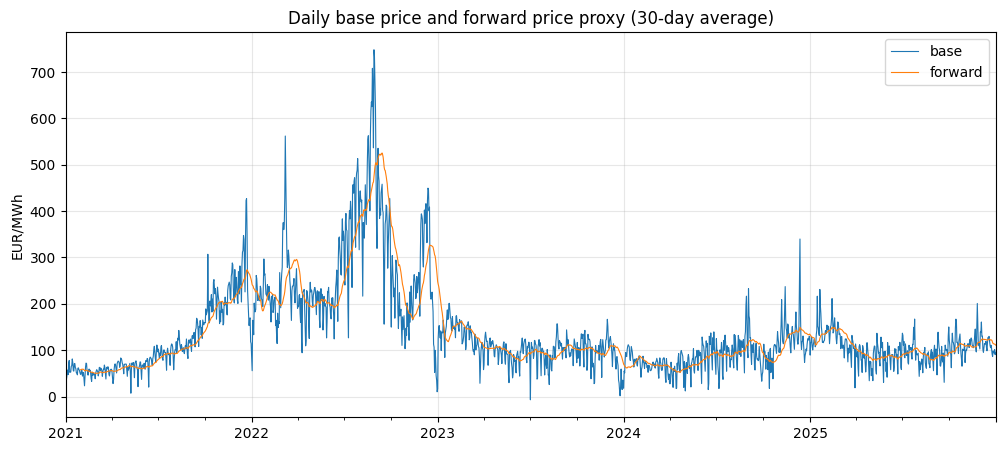

In [2]:
daily["forward"] = daily["base"].rolling(30).mean()

daily[["base", "forward"]].plot(figsize=(12, 5), linewidth=0.8)
plt.title("Daily base price and forward price proxy (30-day average)")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("forward_proxy.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Daily variation margin

Futures are revalued every day. The change in the forward price is settled in cash on the full contract volume, so every 1 EUR/MWh move means 43,800 EUR.

Positive values are cash received from the exchange; negative values are cash paid to the exchange.

In [3]:
volume_mwh = 5 * 8760

daily["margin"] = volume_mwh * daily["forward"].diff()

daily["margin"].describe()

count      1796.000000
mean       1298.592664
std      118491.697884
min     -629315.966667
25%      -43104.370833
50%        2313.941304
75%       49708.741667
max      607342.966667
Name: margin, dtype: float64

## 4. Cumulative cash flows

What matters for liquidity planning is how much cash leaves the company over a period, so daily margin is summed over rolling 7-day and 30-day windows.

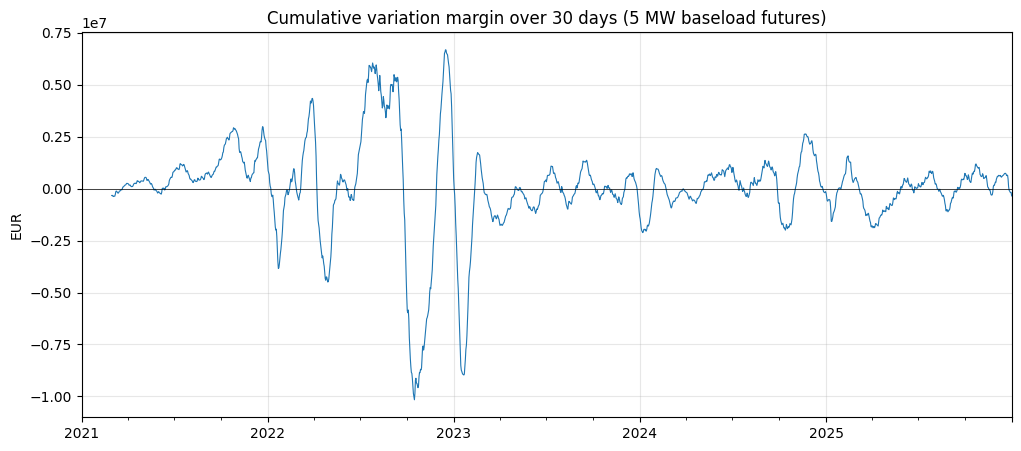

In [4]:
daily["margin_7d"] = daily["margin"].rolling(7).sum()
daily["margin_30d"] = daily["margin"].rolling(30).sum()

daily["margin_30d"].plot(figsize=(12, 5), linewidth=0.8)
plt.axhline(0, color="black", linewidth=0.5)
plt.title("Cumulative variation margin over 30 days (5 MW baseload futures)")
plt.ylabel("EUR")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("margin_30d.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Liquidity-at-Risk

Liquidity-at-Risk applies the logic of VaR to cash: how much cash the company needs, with 95% or 99% confidence, over one week or one month.

### Long position (buyer)

A buyer pays margin when prices fall, so the lower tail of cash flows is relevant.

In [5]:
for horizon in ["margin_7d", "margin_30d"]:
    lar_95 = -daily[horizon].quantile(0.05)
    lar_99 = -daily[horizon].quantile(0.01)
    print(f"{horizon}:  LaR 95% = {lar_95:,.0f} EUR   LaR 99% = {lar_99:,.0f} EUR")

worst_end = daily["margin_30d"].idxmin()
print()
print(f"Largest 30-day outflow: {-daily['margin_30d'].min():,.0f} EUR, period ending {worst_end.date()}")

margin_7d:  LaR 95% = 1,087,839 EUR   LaR 99% = 2,617,612 EUR
margin_30d:  LaR 95% = 3,780,022 EUR   LaR 99% = 8,901,083 EUR

Largest 30-day outflow: 10,161,793 EUR, period ending 2022-10-16


### Short position (seller)

For a seller, such as a generator hedging future output, all cash flows are reversed: margin is paid when prices rise, so the upper tail is relevant.

In [6]:
for horizon in ["margin_7d", "margin_30d"]:
    lar_95 = daily[horizon].quantile(0.95)
    lar_99 = daily[horizon].quantile(0.99)
    print(f"{horizon}:  LaR 95% = {lar_95:,.0f} EUR   LaR 99% = {lar_99:,.0f} EUR")

worst_end = daily["margin_30d"].idxmax()
print()
print(f"Largest 30-day outflow: {daily['margin_30d'].max():,.0f} EUR, period ending {worst_end.date()}")

margin_7d:  LaR 95% = 1,065,320 EUR   LaR 99% = 1,945,377 EUR
margin_30d:  LaR 95% = 3,940,430 EUR   LaR 99% = 5,848,009 EUR

Largest 30-day outflow: 6,680,865 EUR, period ending 2022-12-16


Even a 5 MW position required more than 10 million EUR of cash within one month in autumn 2022, when prices fell sharply after the August peak. Margin is due immediately, even if the position hedges profitable fixed-price sales, so a company can be economically sound and still face a cash shortfall.